# 🧬 Proje 3 · Bölüm 2 — Yapay zeka ile kromozom tanıma ve dijital karyogram
**Seviye: İleri**

Sayım bize "47 kromozom var" der; ama **hangisi fazla?** Bunun için her kromozomun **tipini** (1–22, X, Y) tanımamız gerekir. Uzmanlar bunu uzunluk, sentromer konumu ve **bant deseni** ile yapar. Biz bir **evrişimli sinir ağına (CNN)** bu tanımayı örneklerden öğreteceğiz.

**Akış:** metafaz → nesne bulma (3.1) → her kromozomu dik çevirip kesme → CNN ile tip tahmini → eşleştirme → **dijital karyogram** ve karyotip formülü (ör. 47,XX,+21)

In [1]:
# Google Colab'da çalışıyorsanız proje klasörünü (zip) yükleyin
import os, sys
if "google.colab" in sys.modules and not os.path.exists("veri"):
    from google.colab import files
    print("Lütfen 03_Genetik.zip dosyasını seçin"); files.upload()
    !unzip -q -o 03_Genetik.zip
    %cd 03_Genetik
print("Çalışma klasörü:", os.getcwd())

Çalışma klasörü: /home/claude/SaglikYZ/03_Genetik


In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json, keras
from keras import layers
from PIL import Image
from karyotip_sim import metafaz_uret, KARYOTIPLER
from kromozom_isleme import nesneleri_bul, kesit_al, siniflari_ata, karyotip_yorumu, TIPLER
plt.rcParams["figure.dpi"] = 110
keras.utils.set_random_seed(0)

I0000 00:00:1791823912.238746    2202 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791823913.644310    2202 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Eğitim verisi: binlerce etiketli kromozom kesiti
Bölüm 3.1'deki test görüntülerinden **tamamen ayrı**, 320 yeni metafaz üretiyoruz. Her bulunan nesneyi gerçek etiketle eşleştirip (en az %85 örtüşme) kesitini kaydediyoruz. Kesit: kromozom **ana ekseni boyunca dikey** çevrilir, 80×24 piksellik kutuya yerleştirilir (ölçek korunur → uzunluk bilgisi kaybolmaz).

Toplam kesit: 14692 | eğitim: 12852 | doğrulama: 1840


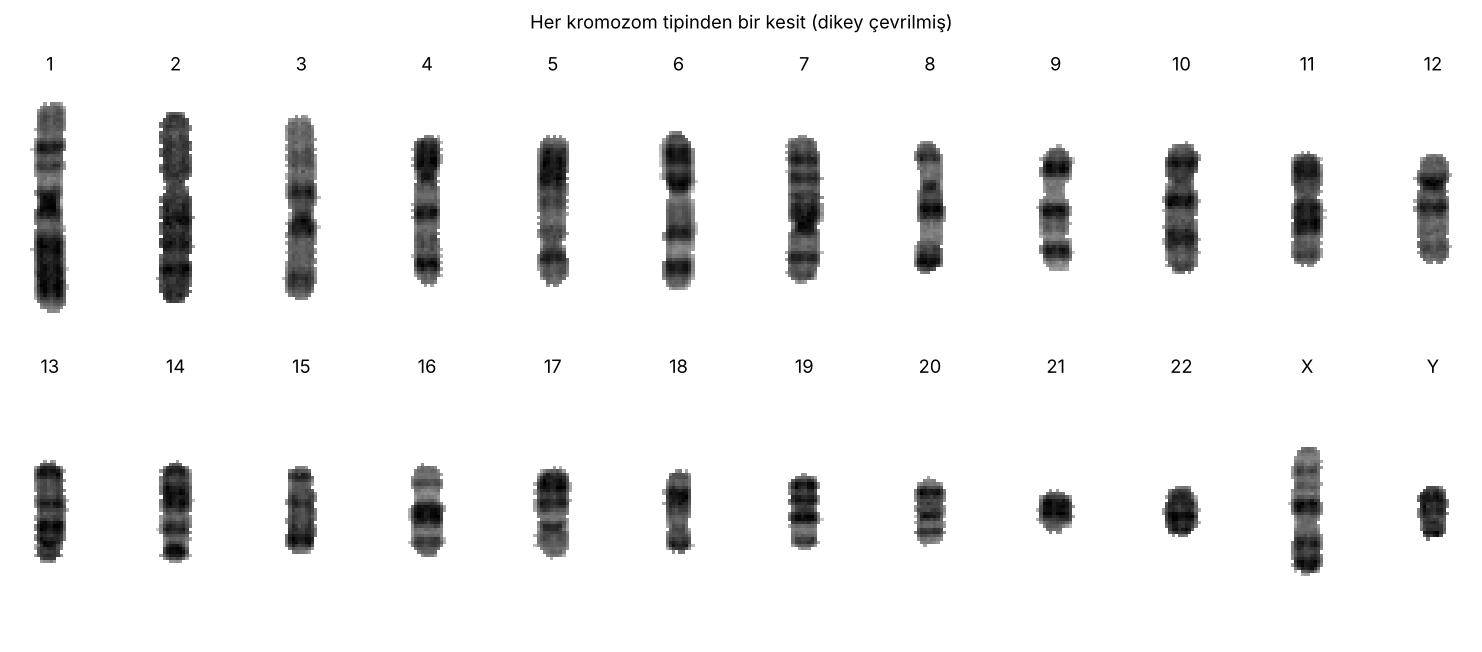

In [3]:
def kesit_veri_seti(tohumlar):
    X, Y, H = [], [], []
    for s in tohumlar:
        kt = list(KARYOTIPLER)[s % 8]
        g, et_gercek, kayit = metafaz_uret(kt, tohum=s, temas_orani=0.0, cekirdek=s % 3)
        et, ns, _ = nesneleri_bul(g)
        for n in ns:
            if n["tur"] != "kromozom": continue
            m = et == n["no"]; ids = et_gercek[m]; ids = ids[ids > 0]
            if len(ids) == 0: continue
            v, c = np.unique(ids, return_counts=True)
            if c.max() / m.sum() < 0.85: continue
            X.append(kesit_al(g, et, n)); Y.append(TIPLER.index(kayit[v[np.argmax(c)] - 1]["tip"])); H.append(s)
    return np.array(X)[..., None], np.array(Y), np.array(H)

X, Y, hucre = kesit_veri_seti(range(20000, 20320))
egt, dog = hucre < 20280, hucre >= 20280          # son 40 hücre doğrulama
print(f"Toplam kesit: {len(X)} | eğitim: {egt.sum()} | doğrulama: {dog.sum()}")

fig, ax = plt.subplots(2, 12, figsize=(14, 6))
for k in range(24):
    a = ax[k // 12, k % 12]; i = np.where(Y == k)[0][0]
    a.imshow(1 - X[i, ..., 0], cmap="gray", vmin=0, vmax=1); a.set_title(TIPLER[k]); a.axis("off")
plt.suptitle("Her kromozom tipinden bir kesit (dikey çevrilmiş)"); plt.tight_layout(); plt.show()

## 2. CNN modeli: 24 sınıflı kromozom tanıyıcı
Kromozom baş aşağı da durabilir; bu yüzden eğitimde görüntüleri rastgele **ters çeviriyoruz** (veri artırma).

Parametre sayısı: 188,024


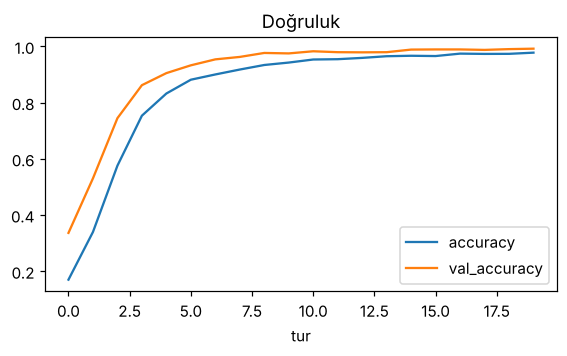

Doğrulama doğruluğu (kromozom başına): 0.9918


In [4]:
giris = keras.Input((80, 24, 1))
x = keras.Sequential([layers.RandomFlip("horizontal_and_vertical")], name="veri_artirma")(giris)
for f in [32, 64, 96]:
    x = layers.Conv2D(f, 3, padding="same", activation="relu")(x); x = layers.MaxPooling2D()(x)
x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(0.3)(x)
cikis = layers.Dense(24, activation="softmax", name="tip")(x)
model = keras.Model(giris, cikis, name="kromozom_cnn")
model.compile(keras.optimizers.Adam(2e-3), "sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"Parametre sayısı: {model.count_params():,}")
gecmis = model.fit(X[egt], Y[egt], validation_data=(X[dog], Y[dog]), epochs=20, batch_size=64, verbose=0,
                   callbacks=[keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)])
h = pd.DataFrame(gecmis.history)
h[["accuracy", "val_accuracy"]].plot(figsize=(6, 3), title="Doğruluk"); plt.xlabel("tur"); plt.show()
print("Doğrulama doğruluğu (kromozom başına):", round(h.val_accuracy.max(), 4))

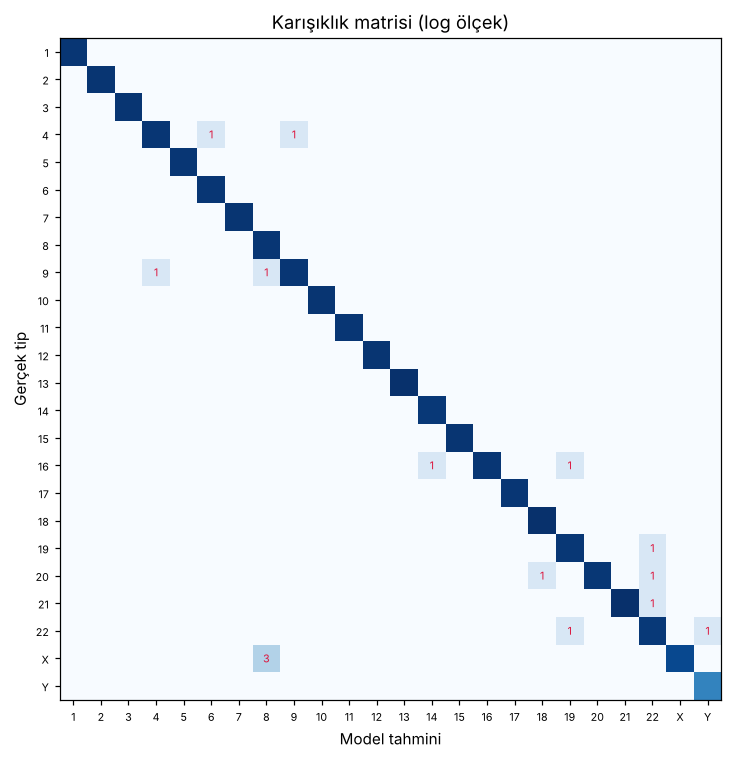

In [5]:
from sklearn.metrics import confusion_matrix
p = model.predict(X[dog], verbose=0).argmax(1)
cm = confusion_matrix(Y[dog], p, labels=range(24))
plt.figure(figsize=(8, 7)); plt.imshow(np.log1p(cm), cmap="Blues")
plt.xticks(range(24), TIPLER, fontsize=7); plt.yticks(range(24), TIPLER, fontsize=7)
plt.xlabel("Model tahmini"); plt.ylabel("Gerçek tip"); plt.title("Karışıklık matrisi (log ölçek)")
for i, j in zip(*np.where((cm > 0) & ~np.eye(24, dtype=bool))):
    plt.text(j, i, cm[i, j], ha="center", va="center", color="crimson", fontsize=7)
plt.tight_layout(); plt.show()

Kırmızı sayılar karışan çiftleri gösterir; genellikle **benzer boyutlu** kromozomlar (ör. 11-12, 19-20, 21-22) karışır — tıpkı insan gözünde olduğu gibi.

## 3. Hücre düzeyinde karar: dijital karyogram
Kromozom başına ~%99 doğruluk iyi görünür; ama bir hücrede 46 kromozom var. **Hepsinin** doğru olma olasılığı ≈ 0,99⁴⁶ ≈ %63! (Doğruluk %98 olsaydı ≈ %40.) Bu yüzden biyolojik bir kısıt ekliyoruz: *her tipten normalde 2 tane bulunur.* En emin olunan tahminlerden başlayarak her tipe en fazla 2 kromozom atıyoruz; bir kromozom ancak modelin de makul olasılık verdiği (≥ %10) başka bir tipe kaydırılabilir. Hiçbir yere sığmayan kromozom en olası tipinde kalır (→ trizomi).

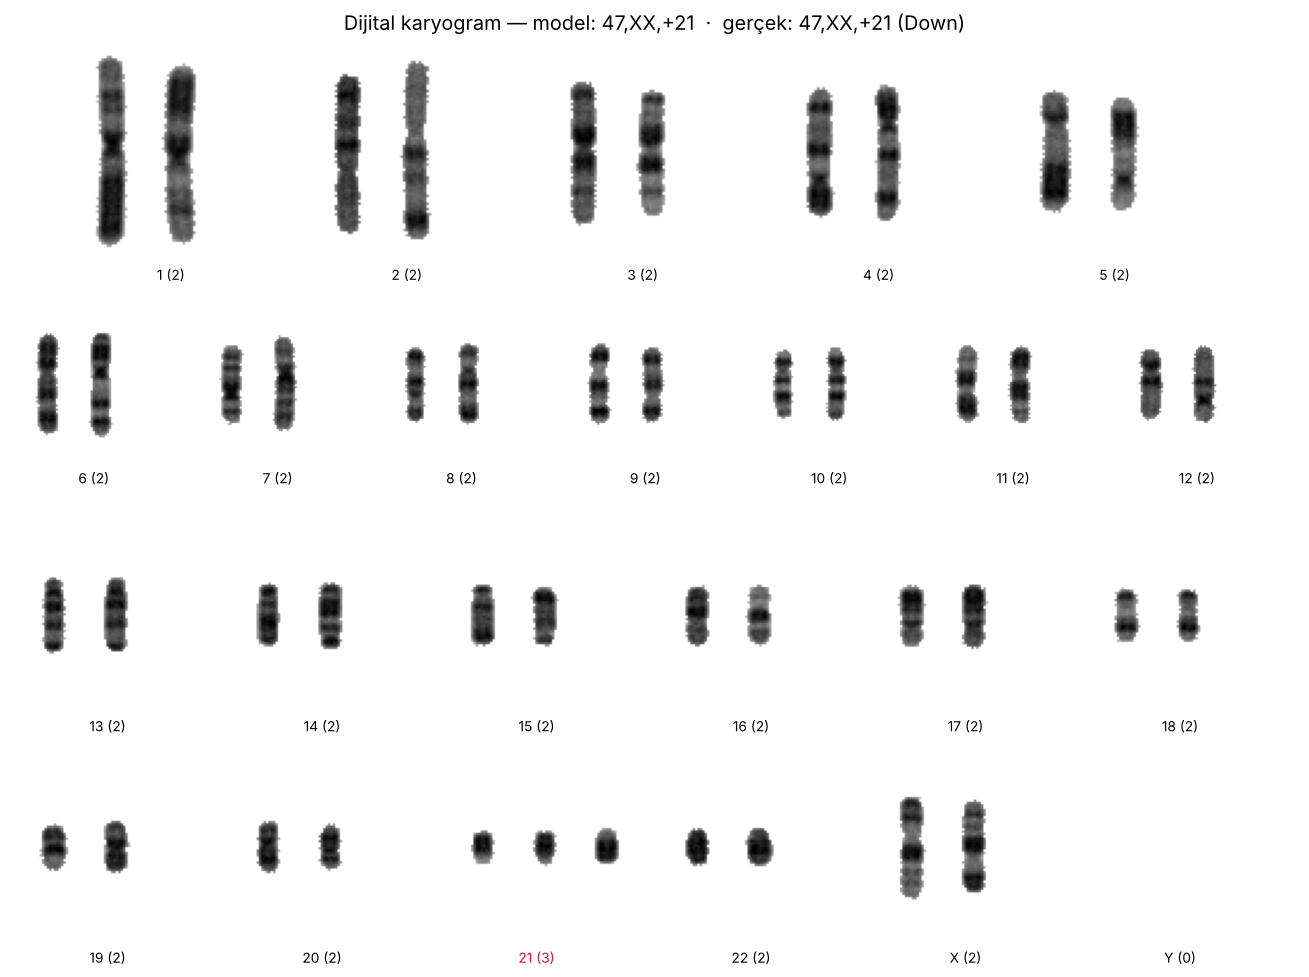

Yorum: Down sendromu (trizomi 21)


In [6]:
def karyotiple(g):
    et, ns, _ = nesneleri_bul(g)
    tekler = [n for n in ns if n["tur"] == "kromozom"]
    K = np.stack([kesit_al(g, et, n) for n in tekler])[..., None]
    P = model.predict(K, verbose=0)
    atama = siniflari_ata(P)
    formul, yorum, sayi = karyotip_yorumu(atama, sum(n["tur"] == "kume" for n in ns))
    return K, P, atama, formul, yorum

def karyogram_ciz(K, atama, baslik):
    satirlar = [list(range(0, 5)), list(range(5, 12)), list(range(12, 18)), list(range(18, 22)) + [22, 23]]
    fig, axes = plt.subplots(4, 1, figsize=(12, 9))
    for ax, satir in zip(axes, satirlar):
        tuval = np.ones((80, len(satir) * 90)); ax.axis("off")
        for s_i, k in enumerate(satir):
            idx = np.where(atama == k)[0]
            for j, i in enumerate(idx[:3]):
                x0 = s_i * 90 + 6 + j * 26
                if x0 + 24 <= tuval.shape[1]: tuval[:, x0:x0 + 24] = np.minimum(tuval[:, x0:x0 + 24], 1 - K[i, ..., 0])
            renk = "crimson" if len(idx) != (1 if k == 23 else 2) and k < 22 else "black"
            ax.text(s_i * 90 + 40, 88, f"{TIPLER[k]} ({len(idx)})", ha="center", fontsize=9, color=renk)
        ax.imshow(tuval, cmap="gray", vmin=0, vmax=1)
    plt.suptitle(baslik, fontsize=13); plt.tight_layout(); plt.show()

etiketler = json.load(open("veri/metafaz/etiketler.json"))
ornek = next(e for e in etiketler if e["karyotip"].startswith("47,XX,+21") and e["zorluk"] == "kolay")
g = np.asarray(Image.open("veri/metafaz/" + ornek["dosya"]).convert("L"))
K, P, atama, formul, yorum = karyotiple(g)
karyogram_ciz(K, atama, f"Dijital karyogram — model: {formul}  ·  gerçek: {ornek['karyotip']}")
print("Yorum:", "; ".join(yorum))

## 4. Tüm test hücrelerinde karyotip doğruluğu
Bölüm 3.1'deki 160 görüntüde (model bunları hiç görmedi) karyotip formülünü tahmin edip gerçekle karşılaştırıyoruz.

In [7]:
def beklenen_formul(kt):
    k = KARYOTIPLER[kt]; n = 44 + len(k["cins"]) + len(k["ek"])
    return f"{n},{''.join(sorted(k['cins']))}" + ("," + ",".join("+" + e for e in k["ek"]) if k["ek"] else "")

kayitlar = []
for e in etiketler:
    g = np.asarray(Image.open("veri/metafaz/" + e["dosya"]).convert("L"))
    _, _, _, formul, _ = karyotiple(g)
    kayitlar.append({"zorluk": e["zorluk"], "gercek": beklenen_formul(e["karyotip"]), "tahmin": formul})
k = pd.DataFrame(kayitlar); k["dogru"] = k.gercek == k.tahmin
print(k.groupby("zorluk").dogru.mean().loc[["kolay", "orta", "zor"]].round(2).to_string())
k[k.zorluk == "kolay"].groupby("gercek").dogru.mean().round(2).to_frame("doğru oranı (kolay hücreler)")

zorluk
kolay    0.79
orta     0.32
zor      0.00


,doğru oranı (kolay hücreler)
gercek,
"45,X",0.8
"46,XX",0.7
"46,XY",1.0
"47,XX,+18",0.7
"47,XX,+21",0.9
"47,XXY",0.9
"47,XY,+13",0.6
"47,XY,+21",0.7


**Yorum:** İyi yayılmış (kolay) hücrelerde sistem yaklaşık **her 5 hücreden 4'ünde** karyotip formülünü tam doğru verir; hataların bir kısmı sayım (değen/çekirdekle örtüşen kromozom), bir kısmı benzer boyutlu kromozomların karışmasından kaynaklanır. Değen kromozomlar sayımı bozduğunda formül de bozulur — bu yüzden gerçek laboratuvarlarda birden fazla hücre (genellikle 20) incelenir ve **uzman onayı** zorunludur.

## 5. Telefona aktarma

In [8]:
import base64, io
from yz_aktar import keras_to_js, js_ile_dogrula
os.makedirs("mobil/www", exist_ok=True)
print(keras_to_js(model, "mobil/www/kromozom_model.js", degisken="KROMOZOM_MODEL", meta={"siniflar": TIPLER}))
js = js_ile_dogrula("mobil/www/yzmotor.js", "mobil/www/kromozom_model.js", "KROMOZOM_MODEL", X[dog][:300])
if js is not None:
    py = model.predict(X[dog][:300], verbose=0)
    print(f"JS ve Python: en büyük olasılık farkı {np.abs(js - py).max():.1e}, sınıf uyumu %{100*np.mean(js.argmax(1) == py.argmax(1)):.0f}")

# Uygulamaya gömülecek örnek metafazlar: her karyotipten, modelin DOĞRU çözdüğü bir kolay test hücresi
# (gösterim amaçlı seçimdir; modelin hata yaptığı hücreler yukarıdaki tabloda görülebilir)
ornekler, gorulen = [], set()
for e, dogru_mu in zip(etiketler, k.dogru):
    if e["zorluk"] != "kolay" or e["karyotip"] in gorulen or not dogru_mu: continue
    gorulen.add(e["karyotip"])
    ornekler.append({"ad": e["karyotip"], "src": "data:image/png;base64," + base64.b64encode(open("veri/metafaz/" + e["dosya"], "rb").read()).decode()})
open("mobil/www/ornek_metafaz.js", "w").write("window.ORNEK_METAFAZ = " + json.dumps(ornekler, ensure_ascii=False) + ";\n")
model.save("model/kromozom_cnn.keras")
print("Gömülen örnekler:", [o["ad"] for o in ornekler])

{'dugum_sayisi': 10, 'boyut_kb': 981}


JS ve Python: en büyük olasılık farkı 9.2e-07, sınıf uyumu %100
Gömülen örnekler: ['46,XX', '46,XY', '47,XX,+21 (Down)', '47,XY,+13 (Patau)', '45,X (Turner)', '47,XXY (Klinefelter)', '47,XY,+21 (Down)', '47,XX,+18 (Edwards)']


## ✅ Çıkarımlar
* Klasik görüntü işleme (bulma, kesme) + derin öğrenme (tanıma) + **biyolojik bilgi** (her tipten 2 adet) birlikte en iyi sonucu verir.
* Hücre düzeyinde doğruluk, kromozom düzeyindeki doğruluktan çok daha zorludur: küçük hatalar birikir.
* Bu sistem yalnızca **sayısal** anomalileri yakalayabilir; translokasyon, delesyon gibi **yapısal** anomaliler için bant deseninin çok daha ayrıntılı karşılaştırılması gerekir.

💡 **Araştırma fikirleri**
1. Sentetik veriyle ön eğitilmiş modeli **az sayıda gerçek karyogramla ince ayar** yapmak (alan uyarlaması / domain adaptation).
2. Tek hücre yerine **20 hücrelik** analizde mozaisizm tespiti (ör. %10 trizomik hücre).
3. Yapısal anomali tespiti için homolog kromozomların bant profillerini karşılaştıran **siyam (Siamese) ağlar**.